In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.applications import VGG16
import matplotlib.pyplot as plt
import numpy as np

In [3]:
train_dir = r'C:\Users\Admin\Downloads\animals\cats_and_dogs_filtered\train'
test_dir = r'C:\Users\Admin\Downloads\animals\cats_and_dogs_filtered\validation'

In [4]:
img_height,img_width =150,150
batch_size=32

In [9]:
train =tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(img_height,img_width),
    batch_size=batch_size,
)
validation =tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(img_height,img_width),
    batch_size=batch_size,
)

Found 2000 files belonging to 2 classes.


Found 1000 files belonging to 2 classes.


In [10]:
class_names = train.class_names
num_classes = len(class_names)
print(f"Detected Classes:{class_names}")

Detected Classes:['cats', 'dogs']


In [13]:
preprocess_input = tf.keras.applications.vgg16.preprocess_input

In [17]:
train = train.map(lambda x,y:(preprocess_input(x),y))
validation = validation.map(lambda x,y:(preprocess_input(x),y))

In [18]:
base_model = VGG16(input_shape=(img_height,img_width,3),include_top=False,weights='imagenet')

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 27s 0us/step


In [19]:
base_model.trainable = False

In [21]:
model = Sequential([
    base_model,
    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.5),
    Dense(num_classes,activation='softmax')
])

In [26]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,763,650 (60.13 MB)

 Trainable params: 1,048,962 (4.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [27]:
history = model.fit(train,epochs=3,validation_data=validation)

Epoch 1/3


d:\Anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 368s 6s/step - accuracy: 0.9665 - loss: 0.6019 - val_accuracy: 0.9480 - val_loss: 0.6962
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 387s 6s/step - accuracy: 0.9615 - loss: 0.6683 - val_accuracy: 0.9660 - val_loss: 0.5112
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 367s 6s/step - accuracy: 0.9730 - loss: 0.4049 - val_accuracy: 0.9510 - val_loss: 0.4070


In [28]:
 plt.figure(figsize=(12,4))

<Figure size 1200x400 with 0 Axes>

<Figure size 1200x400 with 0 Axes>

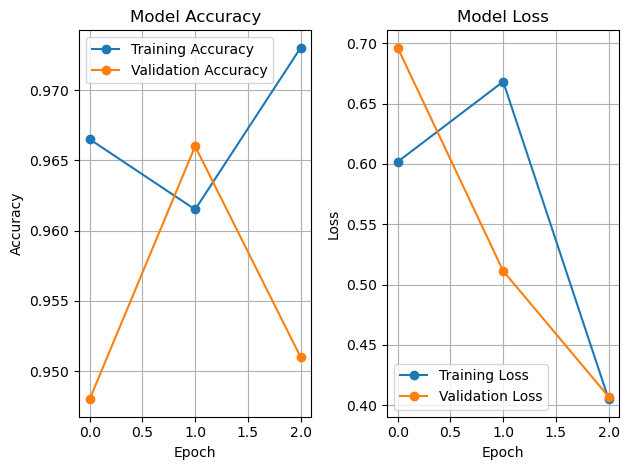

In [29]:
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 677ms/step
Predicted Class: cats
Actual Class: cats


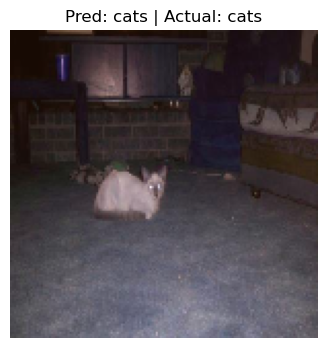

In [30]:
for images,labels in validation.take(1):
    img=images[0]
    actual_label = int(labels[0].numpy())
    break
prediction_prob = model.predict(tf.expand_dims(img, axis=0))
predicted_label = np.argmax(prediction_prob)

print(f"Predicted Class: {class_names[predicted_label]}")
print(f"Actual Class: {class_names[actual_label]}")


plt.figure(figsize=(4, 4))

display_img = (img.numpy() + 127.5) / 255.0 
plt.imshow(np.clip(display_img, 0, 1))
plt.title(f"Pred: {class_names[predicted_label]} | Actual: {class_names[actual_label]}")
plt.axis('off')
plt.show()